In [3]:
import pandas as pd
import numpy as np

In [4]:
# reload the dataset to create the same working set 7000 reference + 300 evaluation split
sms = pd.read_csv(
    "../data/raw/SMSSpamCollection",
    sep="\t",
    header=None,
    names=[
        "label",
        "text"
    ]
)

sms["message_id"] = [
    f"SMS_{i:04d}"
    for i in range(len(sms))
]

print(
    "Messages:",
    len(sms)
)

print(
    sms["label"].value_counts()
)

display(
    sms.head(10)
)

Messages: 5572
label
ham     4825
spam     747
Name: count, dtype: int64


,label,text,message_id
0,ham,"Go until jurong point, crazy.. Available only ...",SMS_0000
1,ham,Ok lar... Joking wif u oni...,SMS_0001
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,SMS_0002
3,ham,U dun say so early hor... U c already then say...,SMS_0003
4,ham,"Nah I don't think he goes to usf, he lives aro...",SMS_0004
5,spam,FreeMsg Hey there darling it's been 3 week's n...,SMS_0005
6,ham,Even my brother is not like to speak with me. ...,SMS_0006
7,ham,As per your request 'Melle Melle (Oru Minnamin...,SMS_0007
8,spam,WINNER!! As a valued network customer you have...,SMS_0008
9,spam,Had your mobile 11 months or more? U R entitle...,SMS_0009


In [5]:
# fixed 1000 message working set
from sklearn.model_selection import (
    train_test_split
)

WORKING_SEED = 42

sms_working, _ = train_test_split(
    sms,
    train_size=1000,
    random_state=WORKING_SEED,
    stratify=sms["label"]
)

sms_working = (
    sms_working
    .copy()
    .reset_index(drop=True)
)

print(
    "Working messages:",
    len(sms_working)
)

print(
    sms_working[
        "label"
    ].value_counts()
)

print(
    sms_working[
        "label"
    ].value_counts(
        normalize=True
    )
)

Working messages: 1000
label
ham     866
spam    134
Name: count, dtype: int64
label
ham     0.866
spam    0.134
Name: proportion, dtype: float64


In [6]:
sms_reference, sms_eval = (
    train_test_split(
        sms_working,
        train_size=700,
        test_size=300,
        random_state=42,
        stratify=sms_working["label"]
    )
)

sms_reference = (
    sms_reference
    .copy()
    .reset_index(drop=True)
)

sms_eval = (
    sms_eval
    .copy()
    .reset_index(drop=True)
)

print(
    "Reference:",
    len(sms_reference)
)

print(
    "Evaluation:",
    len(sms_eval)
)

print(
    "\nReference labels:"
)

print(
    sms_reference[
        "label"
    ].value_counts()
)

print(
    "\nEvaluation labels:"
)

print(
    sms_eval[
        "label"
    ].value_counts()
)

assert len(
    set(
        sms_reference["message_id"]
    )
    &
    set(
        sms_eval["message_id"]
    )
) == 0

Reference: 700
Evaluation: 300

Reference labels:
label
ham     606
spam     94
Name: count, dtype: int64

Evaluation labels:
label
ham     260
spam     40
Name: count, dtype: int64


In [7]:
sms_split = pd.concat(
    [
        sms_reference.assign(
            split="reference"
        ),
        sms_eval.assign(
            split="evaluation"
        )
    ],
    ignore_index=True
)

sms_split.to_csv(
    "../data/processed/"
    "over_polished_sms_split.csv",
    index=False
)

print(
    "Frozen Over-Polished split saved."
)

Frozen Over-Polished split saved.


The transformation will follow these fixed rules:
Original meaning        - preserved
Numbers                  - preserved
URLs                     - preserved
Phone numbers            - preserved
Named entities           - preserved
Original ham/spam label  - preserved
Message count            - preserved
Only linguistic style    - changed

In [8]:
sms_reference, sms_eval = train_test_split(
    sms_working,
    train_size=700,
    test_size=300,
    random_state=42,
    stratify=sms_working["label"]
)

sms_reference = (
    sms_reference
    .copy()
    .reset_index(drop=True)
)

sms_eval = (
    sms_eval
    .copy()
    .reset_index(drop=True)
)

print(
    "Reference:",
    len(sms_reference)
)

print(
    "Evaluation:",
    len(sms_eval)
)

print("\nReference labels:")
print(
    sms_reference[
        "label"
    ].value_counts()
)

print("\nReference proportions:")
print(
    sms_reference[
        "label"
    ].value_counts(
        normalize=True
    )
)

print("\nEvaluation labels:")
print(
    sms_eval[
        "label"
    ].value_counts()
)

print("\nEvaluation proportions:")
print(
    sms_eval[
        "label"
    ].value_counts(
        normalize=True
    )
)

overlap = (
    set(sms_reference["message_id"])
    &
    set(sms_eval["message_id"])
)

print(
    "\nOverlap:",
    len(overlap)
)

assert len(sms_reference) == 700
assert len(sms_eval) == 300
assert len(overlap) == 0

Reference: 700
Evaluation: 300

Reference labels:
label
ham     606
spam     94
Name: count, dtype: int64

Reference proportions:
label
ham     0.865714
spam    0.134286
Name: proportion, dtype: float64

Evaluation labels:
label
ham     260
spam     40
Name: count, dtype: int64

Evaluation proportions:
label
ham     0.866667
spam    0.133333
Name: proportion, dtype: float64

Overlap: 0


In [9]:
from pathlib import Path

Path(
    "../data/processed"
).mkdir(
    exist_ok=True
)

sms_split = pd.concat(
    [
        sms_reference.assign(
            split="reference"
        ),
        sms_eval.assign(
            split="evaluation"
        )
    ],
    ignore_index=True
)

sms_split.to_csv(
    "../data/processed/"
    "over_polished_sms_split.csv",
    index=False
)

print(
    "Frozen Over-Polished split saved."
)

Frozen Over-Polished split saved.


Deterministic style transformation: expanding SMS abbreviations and contractions, normalizing punctuation/capitalization, and replacing certain colloquial forms with more formal equivalents.

In [10]:
import importlib
import src.defects as defects

In [11]:
importlib.reload(defects)

<module 'src.defects' from '/Users/jessica/fidelity-metric-lab/src/defects.py'>

In [12]:
from src.defects import (
    over_polish_sms_text,
    find_over_polished_candidates
)

In [13]:
# find candidates for the transformation 
over_polished_candidates = (
    find_over_polished_candidates(
        sms_eval
    )
)

print(
    "Evaluation messages:",
    len(sms_eval)
)

print(
    "Eligible messages:",
    len(
        over_polished_candidates
    )
)

print(
    "\nEligible by label:"
)

print(
    over_polished_candidates[
        "label"
    ].value_counts()
)

print(
    "\nStyle changes:"
)

print(
    over_polished_candidates[
        "n_style_changes"
    ].describe()
)

display(
    over_polished_candidates[
        [
            "message_id",
            "label",
            "n_style_changes",
            "original_text",
            "polished_text"
        ]
    ].head(15)
)

Evaluation messages: 300
Eligible messages: 226

Eligible by label:
label
ham     190
spam     36
Name: count, dtype: int64

Style changes:
count    226.000000
mean       2.035398
std        1.264413
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max        7.000000
Name: n_style_changes, dtype: float64


,message_id,label,n_style_changes,original_text,polished_text
0,SMS_5520,ham,2,No. I dont want to hear anything,No. I do not want to hear anything.
1,SMS_2287,ham,1,I have had two more letters from . I will copy...,I have had two more letters from . I will copy...
2,SMS_2431,ham,1,How was txting and driving,How was txting and driving.
3,SMS_3792,spam,3,"Twinks, bears, scallies, skins and jocks are c...","Twinks, bears, scallies, skins and jocks are c..."
4,SMS_3442,spam,1,Get a FREE mobile video player FREE movie. To ...,Get a FREE mobile video player FREE movie. To ...
5,SMS_4863,spam,4,**FREE MESSAGE**Thanks for using the Auction S...,**FREE MESSAGE**Thank you for using the Auctio...
6,SMS_1199,ham,3,Al he does is moan at me if n e thin goes wron...,Al he does is moan at me if n e thin goes wron...
7,SMS_3275,ham,2,Thanx a lot...,Thank you a lot...
8,SMS_2162,ham,1,Is she replying. Has boye changed his phone nu...,Is she replying. Has boye changed his phone nu...
9,SMS_1937,ham,1,"My planning usually stops at ""find hella weed,...","My planning usually stops at ""find hella weed,..."


**How the severity levels will be determined**

Rather than simply selecting the first 30, 90, and 180 eligible items, we will maintain approximately the same ham/spam ratio found in the evaluation set:

Evaluation:

|260 ham / 40 spam|
|------------------|
|86.67% / 13.33%|




|Severity|	Total affected|	Ham	/ Spam|
|---------|-------------|-------------|
|10%	|30	|26	/4|
|30%	|90	|78	/ 12|
|60%	|180	|156	/ 24|

In [14]:
importlib.reload(defects)

from src.defects import (
    make_over_polished_plan,
    inject_over_polished_language
)

In [15]:
over_polished_plan = (
    make_over_polished_plan(
        sms_eval,
        seed=42
    )
)

print(
    "Eligible plan messages:",
    len(over_polished_plan)
)

print(
    "\nBy label:"
)

print(
    over_polished_plan[
        "label"
    ].value_counts()
)

display(
    over_polished_plan.head(10)
)

Eligible plan messages: 226

By label:
label
ham     190
spam     36
Name: count, dtype: int64


,message_id,label,original_text,polished_text,n_style_changes,class_rank
0,SMS_4923,ham,Hi Dear Call me its urgnt. I don't know whats ...,Hi Dear Call me its urgnt. I do not know whats...,2,1
1,SMS_2977,ham,I love u 2 my little pocy bell I am sorry but ...,I love you 2 my little pocy bell I am sorry bu...,3,2
2,SMS_3091,ham,Am going to take bath ill place the key in win...,Am going to take bath I will place the key in ...,2,3
3,SMS_1872,ham,Dont know supports ass and srt i thnk. I think...,Do not know supports ass and srt i thnk. I thi...,3,4
4,SMS_2022,ham,"I don't have anybody's number, I still haven't...","I do not have anybody's number, I still haven'...",2,5
5,SMS_2027,ham,"Nah man, my car is meant to be crammed full of...","Nah man, my car is meant to be crammed full of...",1,6
6,SMS_3096,ham,Olol i printed out a forum post by a guy with ...,Olol i printed out a forum post by a guy with ...,2,7
7,SMS_0960,ham,Where @,Where @.,1,8
8,SMS_2542,ham,I dont. Can you send it to me. Plus how's mode.,I do not. Can you send it to me. Plus how's mode.,1,9
9,SMS_5219,ham,Pls she needs to dat slowly or she will vomit ...,Please she needs to dat slowly or she will vom...,2,10


In [16]:
OVER_POLISHED_SEVERITIES = [
    0.10,
    0.30,
    0.60
]

over_polished_results = {}

for severity in (
    OVER_POLISHED_SEVERITIES
):

    defective, audit = (
        inject_over_polished_language(
            sms_eval,
            over_polished_plan,
            severity
        )
    )

    over_polished_results[
        severity
    ] = {
        "defective":
            defective,

        "audit":
            audit
    }

    print(
        f"{severity:.0%} | "
        f"affected={len(audit)}"
    )

    print(
        audit[
            "label"
        ].value_counts()
    )

    print()

10% | affected=30
label
ham     26
spam     4
Name: count, dtype: int64

30% | affected=90
label
ham     78
spam    12
Name: count, dtype: int64

60% | affected=180
label
ham     156
spam     24
Name: count, dtype: int64



In [17]:
# nested validation 
ids_10 = set(
    over_polished_results[
        0.10
    ]["audit"]["message_id"]
)

ids_30 = set(
    over_polished_results[
        0.30
    ]["audit"]["message_id"]
)

ids_60 = set(
    over_polished_results[
        0.60
    ]["audit"]["message_id"]
)

assert ids_10.issubset(
    ids_30
)

assert ids_30.issubset(
    ids_60
)

print(
    "Nested severity validation passed."
)

print(
    len(ids_10),
    len(ids_30),
    len(ids_60)
)

Nested severity validation passed.
30 90 180


### Over-Polished Language Definition

Over-Polished Language was operationalized as a deterministic
style-only transformation of SMS messages. The transformation expands
common SMS abbreviations and contractions, applies mild formal lexical
substitutions, normalizes punctuation and capitalization, and preserves
protected factual spans such as URLs, telephone numbers, monetary
amounts, and numeric expressions.

No fixed introductory or closing phrase was added, preventing the defect
from being represented by a trivial repeated lexical marker. Messages
were considered eligible only when at least one explicit stylistic
transformation was applied.

Severity was defined through defect prevalence rather than transformation
magnitude. Nested subsets containing 30, 90, and 180 of the 300
evaluation messages were used for the 10%, 30%, and 60% conditions.
The subsets were stratified to preserve approximately the original
ham/spam composition of the evaluation set. Each selected message has
one fixed polished version that is reused across all applicable severity
levels.

### Semantic Representation for Over-Polished Language

Unlike Entity Inconsistency and Missing Cross-Channel Reference, whose
experimental unit was an entire multi-message campaign, Over-Polished
Language is evaluated at the individual SMS-message level. Therefore,
campaign serialization and message-level chunk aggregation are not used.

The same frozen general-purpose semantic encoder,
`sentence-transformers/all-MiniLM-L6-v2`, with the same fixed model
revision and 384-dimensional L2-normalized output, is retained. No
fine-tuning or style-specific features are introduced.

This design tests whether a general semantic representation preserves
enough stylistic information to distinguish original messages from
style-preserving over-polished rewrites. Because the experimental unit
has changed from campaign embeddings to individual-message embeddings,
the MMD bandwidth used in the previous structural experiments is not
reused. A new RBF bandwidth is estimated once using only the 700 clean
reference-message embeddings and is then frozen for all Over-Polished
Language conditions.

The paired testing design remains unchanged: each clean evaluation
message is compared with its polished counterpart, while severity is
controlled exclusively through the proportion of affected messages.

Here, each experimental unit is an individual SMS, not a campaign. Therefore:
We do not need `serialize_campaign_dataset()` or, likely, chunking.

**Exclude temporarily:** 

    - number_of_contractions
    - abbreviation_count
    - formal_word_count
    - punctuation_score
    - politeness_score
    - grammar_score
    - average_word_length specifically designed for polish

In [18]:
# load the embedding model 
import json

from sentence_transformers import SentenceTransformer


with open(
    "../results/semantic_embedding_configuration.json",
    "r"
) as f:

    semantic_config = json.load(f)


MODEL_NAME = semantic_config["model"]
MODEL_REVISION = semantic_config["revision"]

EMBEDDING_BATCH_SIZE = 64


embedding_model = SentenceTransformer(
    MODEL_NAME,
    revision=MODEL_REVISION
)


print(
    "Model:",
    MODEL_NAME
)

print(
    "Frozen revision:",
    MODEL_REVISION
)

print(
    "Embedding dimension:",
    embedding_model.get_sentence_embedding_dimension()
)

print(
    "Maximum sequence length:",
    embedding_model.max_seq_length
)

Model: sentence-transformers/all-MiniLM-L6-v2
Frozen revision: 1110a243fdf4706b3f48f1d95db1a4f5529b4d41
Embedding dimension: 384
Maximum sequence length: 256


In [19]:
# prepare severities 
def prepare_message_condition(df):

    return (
        df[
            [
                "message_id",
                "label",
                "text"
            ]
        ]
        .sort_values(
            "message_id"
        )
        .reset_index(drop=True)
    )


over_polished_text_sets = {}

over_polished_text_sets[
    "reference"
] = prepare_message_condition(
    sms_reference
)

over_polished_text_sets[
    "clean"
] = prepare_message_condition(
    sms_eval
)


for severity in [
    0.10,
    0.30,
    0.60
]:

    over_polished_text_sets[
        severity
    ] = prepare_message_condition(
        over_polished_results[
            severity
        ]["defective"]
    )


for condition, df in (
    over_polished_text_sets.items()
):

    print(
        condition,
        df.shape
    )

reference (700, 3)
clean (300, 3)
0.1 (300, 3)
0.3 (300, 3)
0.6 (300, 3)


In [20]:
# validate alignment 
clean_ids = (
    over_polished_text_sets[
        "clean"
    ]["message_id"]
    .tolist()
)

clean_labels = (
    over_polished_text_sets[
        "clean"
    ]["label"]
    .tolist()
)


for severity in [
    0.10,
    0.30,
    0.60
]:

    defective = (
        over_polished_text_sets[
            severity
        ]
    )

    assert (
        defective[
            "message_id"
        ].tolist()
        ==
        clean_ids
    )

    assert (
        defective[
            "label"
        ].tolist()
        ==
        clean_labels
    )


print(
    "Message IDs and labels are "
    "perfectly aligned across conditions."
)

Message IDs and labels are perfectly aligned across conditions.


In [21]:
# token length summary 
length_records = []


for condition in [
    "reference",
    "clean",
    0.10,
    0.30,
    0.60
]:

    lengths = []

    for text in (
        over_polished_text_sets[
            condition
        ]["text"]
    ):

        encoded = (
            embedding_model.tokenizer(
                text,
                add_special_tokens=True,
                truncation=False
            )
        )

        lengths.append(
            len(
                encoded[
                    "input_ids"
                ]
            )
        )

    length_records.append({
        "condition":
            condition,

        "n_messages":
            len(lengths),

        "mean_tokens":
            np.mean(
                lengths
            ),

        "max_tokens":
            max(
                lengths
            ),

        "over_limit":
            sum(
                length
                >
                embedding_model.max_seq_length
                for length in lengths
            )
    })


over_polished_length_summary = (
    pd.DataFrame(
        length_records
    )
)

display(
    over_polished_length_summary
)

,condition,n_messages,mean_tokens,max_tokens,over_limit
0,reference,700,24.861429,127,0
1,clean,300,25.233333,125,0
2,0.1,300,25.246667,125,0
3,0.3,300,25.266667,125,0
4,0.6,300,25.290000,123,0


In [22]:
# verify for truncation 
assert (
    over_polished_length_summary[
        "over_limit"
    ].sum()
    == 0
), (
    "At least one SMS exceeds the model "
    "sequence-length limit. Do not encode yet."
)


print(
    "All SMS messages fit within "
    "the model sequence-length limit."
)

All SMS messages fit within the model sequence-length limit.


In [23]:
import src.representations as representations
importlib.reload(
    representations
)

from src.representations import (
    encode_text_messages
)

In [24]:
over_polished_reference_embeddings, reference_runtime = (
    encode_text_messages(
        over_polished_text_sets[
            "reference"
        ],
        embedding_model,
        text_column="text",
        batch_size=EMBEDDING_BATCH_SIZE,
        normalize_embeddings=True
    )
)


print(
    "Reference embedding shape:",
    over_polished_reference_embeddings.shape
)

print(
    "Runtime:",
    round(
        reference_runtime,
        2
    ),
    "seconds"
)

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

Reference embedding shape: (700, 384)
Runtime: 9.86 seconds


In [25]:
# validate reference embeddings 
assert (
    over_polished_reference_embeddings.shape
    ==
    (700, 384)
)

assert np.isfinite(
    over_polished_reference_embeddings
).all()


reference_norms = (
    np.linalg.norm(
        over_polished_reference_embeddings,
        axis=1
    )
)

assert np.allclose(
    reference_norms,
    1.0,
    atol=1e-5
)


print(
    "Reference embeddings passed validation."
)

Reference embeddings passed validation.


In [26]:
# use median heruristic for sigma 
from src.metrics import (
    median_heuristic_sigma
)


OVER_POLISHED_MMD_SIGMA = (
    median_heuristic_sigma(
        over_polished_reference_embeddings
    )
)


print(
    "Frozen Over-Polished MMD sigma:",
    OVER_POLISHED_MMD_SIGMA
)

Frozen Over-Polished MMD sigma: 1.3281240463256836


In [27]:
# save configuration 
from pathlib import Path
import json


Path(
    "../results"
).mkdir(
    exist_ok=True
)


over_polished_embedding_config = {
    "model":
        MODEL_NAME,

    "revision":
        MODEL_REVISION,

    "experimental_unit":
        "individual_sms",

    "embedding_dimension":
        384,

    "normalized":
        True,

    "mmd_sigma_rule":
        "clean-reference median heuristic",

    "reference_messages":
        700,

    "mmd_sigma":
        OVER_POLISHED_MMD_SIGMA
}


with open(
    "../results/"
    "over_polished_embedding_configuration.json",
    "w"
) as f:

    json.dump(
        over_polished_embedding_config,
        f,
        indent=4
    )


print(
    "Over-Polished embedding "
    "configuration saved."
)

Over-Polished embedding configuration saved.


In [28]:
OVER_POLISHED_CONDITIONS = [
    "clean",
    0.10,
    0.30,
    0.60
]

over_polished_embedding_arrays = {}
over_polished_embedding_runtimes = {}


for condition in (
    OVER_POLISHED_CONDITIONS
):

    embeddings, runtime = (
        encode_text_messages(
            over_polished_text_sets[
                condition
            ],
            embedding_model,
            text_column="text",
            batch_size=(
                EMBEDDING_BATCH_SIZE
            ),
            normalize_embeddings=True
        )
    )

    over_polished_embedding_arrays[
        condition
    ] = embeddings

    over_polished_embedding_runtimes[
        condition
    ] = runtime

    print(
        f"{str(condition):>5} | "
        f"shape={embeddings.shape} | "
        f"runtime={runtime:.2f} s"
    )

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

clean | shape=(300, 384) | runtime=5.96 s


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

  0.1 | shape=(300, 384) | runtime=7.25 s


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

  0.3 | shape=(300, 384) | runtime=6.01 s


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

  0.6 | shape=(300, 384) | runtime=6.02 s


In [29]:
# validate the matrices 
for condition in (
    OVER_POLISHED_CONDITIONS
):

    X = (
        over_polished_embedding_arrays[
            condition
        ]
    )

    assert (
        X.shape
        ==
        (300, 384)
    )

    assert np.isfinite(
        X
    ).all()

    norms = np.linalg.norm(
        X,
        axis=1
    )

    assert np.allclose(
        norms,
        1.0,
        atol=1e-5
    )


print(
    "All Over-Polished embedding "
    "matrices passed validation."
)

All Over-Polished embedding matrices passed validation.


In [30]:
# convert to dfs
EMBEDDING_FEATURES = [
    f"emb_{i:03d}"
    for i in range(
        384
    )
]


over_polished_embeddings = {}


for condition in (
    OVER_POLISHED_CONDITIONS
):

    embedding_df = pd.DataFrame(
        over_polished_embedding_arrays[
            condition
        ],
        columns=EMBEDDING_FEATURES
    )

    embedding_df.insert(
        0,
        "message_id",
        over_polished_text_sets[
            condition
        ][
            "message_id"
        ].to_numpy()
    )

    over_polished_embeddings[
        condition
    ] = embedding_df


print(
    "Clean embedding DataFrame:",
    over_polished_embeddings[
        "clean"
    ].shape
)

Clean embedding DataFrame: (300, 385)


In [31]:
EMBEDDING_FEATURES = [
    f"emb_{i:03d}"
    for i in range(
        384
    )
]


over_polished_embeddings = {}


for condition in (
    OVER_POLISHED_CONDITIONS
):

    embedding_df = pd.DataFrame(
        over_polished_embedding_arrays[
            condition
        ],
        columns=EMBEDDING_FEATURES
    )

    embedding_df.insert(
        0,
        "message_id",
        over_polished_text_sets[
            condition
        ][
            "message_id"
        ].to_numpy()
    )

    over_polished_embeddings[
        condition
    ] = embedding_df


print(
    "Clean embedding DataFrame:",
    over_polished_embeddings[
        "clean"
    ].shape
)

Clean embedding DataFrame: (300, 385)


In [32]:
# see which emeddings changed
clean_embeddings_indexed = (
    over_polished_embeddings[
        "clean"
    ]
    .set_index(
        "message_id"
    )
    .sort_index()
)


for severity in [
    0.10,
    0.30,
    0.60
]:

    defective = (
        over_polished_embeddings[
            severity
        ]
        .set_index(
            "message_id"
        )
        .sort_index()
    )

    differences = (
        defective[
            EMBEDDING_FEATURES
        ].to_numpy()
        -
        clean_embeddings_indexed[
            EMBEDDING_FEATURES
        ].to_numpy()
    )

    distances = np.linalg.norm(
        differences,
        axis=1
    )

    changed_ids = set(
        clean_embeddings_indexed.index[
            distances > 1e-8
        ]
    )

    expected_ids = set(
        over_polished_results[
            severity
        ]["audit"][
            "message_id"
        ]
    )

    print(
        f"{severity:.0%}: "
        f"changed={len(changed_ids)}, "
        f"expected={len(expected_ids)}, "
        f"exact match="
        f"{changed_ids == expected_ids}"
    )

    assert (
        changed_ids
        ==
        expected_ids
    )

10%: changed=30, expected=30, exact match=True
30%: changed=88, expected=90, exact match=False


AssertionError: 

In [33]:
for severity in [
    0.10,
    0.30,
    0.60
]:

    clean_text = (
        over_polished_text_sets["clean"]
        .set_index("message_id")
        .sort_index()
    )

    defective_text = (
        over_polished_text_sets[severity]
        .set_index("message_id")
        .sort_index()
    )

    text_changed_ids = set(
        clean_text.index[
            clean_text["text"]
            != defective_text["text"]
        ]
    )

    expected_ids = set(
        over_polished_results[
            severity
        ]["audit"]["message_id"]
    )

    print(
        f"{severity:.0%}: "
        f"text changed={len(text_changed_ids)}, "
        f"expected={len(expected_ids)}, "
        f"exact match={text_changed_ids == expected_ids}"
    )

10%: text changed=30, expected=30, exact match=True
30%: text changed=90, expected=90, exact match=True
60%: text changed=180, expected=180, exact match=True


In [34]:
for severity in [
    0.10,
    0.30,
    0.60
]:

    defective = (
        over_polished_embeddings[
            severity
        ]
        .set_index("message_id")
        .sort_index()
    )

    clean_array = (
        clean_embeddings_indexed[
            EMBEDDING_FEATURES
        ].to_numpy()
    )

    defective_array = (
        defective[
            EMBEDDING_FEATURES
        ].to_numpy()
    )

    distances = np.linalg.norm(
        defective_array - clean_array,
        axis=1
    )

    expected_ids = set(
        over_polished_results[
            severity
        ]["audit"]["message_id"]
    )

    ordered_ids = (
        clean_embeddings_indexed
        .index
        .to_numpy()
    )

    affected_mask = np.array([
        message_id in expected_ids
        for message_id in ordered_ids
    ])

    unaffected_distances = distances[
        ~affected_mask
    ]

    affected_distances = distances[
        affected_mask
    ]

    print(
        f"\nSeverity {severity:.0%}"
    )

    print(
        "UNAFFECTED:"
    )

    print(
        "  max distance:",
        unaffected_distances.max()
    )

    print(
        "  mean distance:",
        unaffected_distances.mean()
    )

    print(
        "AFFECTED:"
    )

    print(
        "  min distance:",
        affected_distances.min()
    )

    print(
        "  mean distance:",
        affected_distances.mean()
    )


Severity 10%
UNAFFECTED:
  max distance: 0.0
  mean distance: 0.0
AFFECTED:
  min distance: 0.046466522
  mean distance: 0.18985817

Severity 30%
UNAFFECTED:
  max distance: 0.0
  mean distance: 0.0
AFFECTED:
  min distance: 0.0
  mean distance: 0.20280327

Severity 60%
UNAFFECTED:
  max distance: 0.0
  mean distance: 0.0
AFFECTED:
  min distance: 0.0
  mean distance: 0.20664431


In [35]:
# how many messages have identical embedding 
ZERO_TOLERANCE = 1e-8

zero_change_records = []


for severity in [
    0.10,
    0.30,
    0.60
]:

    defective = (
        over_polished_embeddings[
            severity
        ]
        .set_index("message_id")
        .sort_index()
    )

    clean_array = (
        clean_embeddings_indexed[
            EMBEDDING_FEATURES
        ].to_numpy()
    )

    defective_array = (
        defective[
            EMBEDDING_FEATURES
        ].to_numpy()
    )

    distances = np.linalg.norm(
        defective_array
        -
        clean_array,
        axis=1
    )

    ordered_ids = (
        clean_embeddings_indexed
        .index
        .to_numpy()
    )

    affected_ids = set(
        over_polished_results[
            severity
        ]["audit"]["message_id"]
    )

    affected_mask = np.array([
        message_id in affected_ids
        for message_id in ordered_ids
    ])

    affected_distances = (
        distances[
            affected_mask
        ]
    )

    affected_message_ids = (
        ordered_ids[
            affected_mask
        ]
    )

    zero_mask = (
        affected_distances
        <= ZERO_TOLERANCE
    )

    zero_ids = (
        affected_message_ids[
            zero_mask
        ]
    )

    print(
        f"{severity:.0%}: "
        f"affected={affected_mask.sum()}, "
        f"zero embedding change={zero_mask.sum()}"
    )

    for message_id in zero_ids:

        zero_change_records.append({
            "severity":
                severity,

            "message_id":
                message_id
        })


zero_embedding_changes = (
    pd.DataFrame(
        zero_change_records
    )
)

10%: affected=30, zero embedding change=0
30%: affected=90, zero embedding change=2
60%: affected=180, zero embedding change=7


In [36]:
severity = 0.60

zero_ids_60 = set(
    zero_embedding_changes.loc[
        zero_embedding_changes[
            "severity"
        ] == severity,
        "message_id"
    ]
)


zero_examples = (
    over_polished_results[
        severity
    ]["audit"]
    .loc[
        lambda df:
            df["message_id"]
            .isin(zero_ids_60),
        [
            "message_id",
            "label",
            "n_style_changes",
            "original_text",
            "polished_text"
        ]
    ]
)


display(
    zero_examples
)

,message_id,label,n_style_changes,original_text,polished_text
64,SMS_1452,ham,1,Ya! when are ü taking ure practical lessons? I...,Ya! When are ü taking ure practical lessons? I...
74,SMS_4668,ham,1,I send the print outs da.,I send the print outs da.
102,SMS_4161,ham,1,i felt so...not any conveying reason.. Ese he....,I felt so...not any conveying reason.. Ese he....
114,SMS_3843,ham,2,"chile, please! It's only a &lt;DECIMAL&gt; h...","Chile, please! It's only a &lt;DECIMAL&gt; hou..."
124,SMS_3203,ham,1,Okay lor... Wah... like that def they wont let...,Okay lor... Wah... Like that def they wont let...
125,SMS_2717,ham,1,"House-Maid is the murderer, coz the man was mu...","House-Maid is the murderer, coz the man was mu..."
150,SMS_0436,ham,1,The message sent is askin for &lt;#&gt; dolla...,The message sent is askin for &lt;#&gt; dollar...


In [37]:
tokenizer_records = []


for _, row in zero_examples.iterrows():

    original_tokens = (
        embedding_model.tokenizer(
            row["original_text"],
            add_special_tokens=True,
            truncation=False
        )["input_ids"]
    )

    polished_tokens = (
        embedding_model.tokenizer(
            row["polished_text"],
            add_special_tokens=True,
            truncation=False
        )["input_ids"]
    )

    tokenizer_records.append({
        "message_id":
            row["message_id"],

        "same_token_ids":
            original_tokens
            ==
            polished_tokens,

        "original_n_tokens":
            len(original_tokens),

        "polished_n_tokens":
            len(polished_tokens)
    })


zero_tokenizer_check = (
    pd.DataFrame(
        tokenizer_records
    )
)


display(
    zero_tokenizer_check
)

,message_id,same_token_ids,original_n_tokens,polished_n_tokens
0,SMS_1452,True,19,19
1,SMS_4668,True,9,9
2,SMS_4161,True,25,25
3,SMS_3843,True,42,42
4,SMS_3203,True,39,39
5,SMS_2717,True,48,48
6,SMS_0436,True,38,38


### Representation-Level Blind Cases

Validation confirmed that all unaffected messages produced exactly the
same semantic embeddings across conditions, demonstrating correct
clean/defective alignment.

However, at the 30% and 60% severity levels, some textually modified
messages produced embeddings identical to their clean counterparts.
These cases were retained rather than removed or rewritten. Requiring
every injected stylistic modification to alter the embedding would bias
the experiment toward transformations already known to be visible to
the selected representation.

This result therefore represents a legitimate representation-level blind
spot: a textual style modification does not necessarily imply a change
in a general-purpose semantic embedding. Additional tokenizer inspection
was used to determine whether these invisible transformations were
collapsed during tokenization or later by the semantic encoder.


### Tokenizer-Level Blind Cases

A small subset of textually modified messages produced exactly the same
semantic embedding as their clean counterparts. No such cases occurred
at 10% prevalence, while 2 of 90 affected messages at 30% and 7 of 180
affected messages at 60% produced zero embedding displacement.

Inspection of these cases showed that the original and polished versions
also produced identical tokenizer input IDs. The invisible transformations
were primarily superficial changes such as capitalization and whitespace
normalization. Therefore, these differences were removed by the tokenizer
before reaching the Transformer encoder.

This provides a representation-level blind spot rather than a metric
failure. For these messages, C2ST, MMD, and Energy Distance receive
identical vectors for the clean and polished versions and therefore have
no representation-level information from which to detect the textual
change.

These cases were intentionally retained. Removing or rewriting them would
bias the experiment toward stylistic transformations already known to be
visible to the selected semantic representation.

In [38]:
# embedding general change 
embedding_change_records = []


for severity in [
    0.10,
    0.30,
    0.60
]:

    defective = (
        over_polished_embeddings[
            severity
        ]
        .set_index("message_id")
        .sort_index()
    )

    clean_array = (
        clean_embeddings_indexed[
            EMBEDDING_FEATURES
        ].to_numpy()
    )

    defective_array = (
        defective[
            EMBEDDING_FEATURES
        ].to_numpy()
    )

    distances = np.linalg.norm(
        defective_array
        -
        clean_array,
        axis=1
    )

    cosine_similarity = np.sum(
        clean_array
        *
        defective_array,
        axis=1
    )

    affected_ids = set(
        over_polished_results[
            severity
        ]["audit"]["message_id"]
    )

    ordered_ids = (
        clean_embeddings_indexed
        .index
        .to_numpy()
    )

    affected_mask = np.array([
        message_id in affected_ids
        for message_id in ordered_ids
    ])

    affected_distances = (
        distances[
            affected_mask
        ]
    )

    embedding_change_records.append({
        "severity":
            severity,

        "affected_messages":
            int(
                affected_mask.sum()
            ),

        "zero_embedding_change":
            int(
                (
                    affected_distances
                    <= 1e-8
                ).sum()
            ),

        "mean_change_all":
            distances.mean(),

        "mean_change_affected":
            affected_distances.mean(),

        "median_change_affected":
            np.median(
                affected_distances
            ),

        "max_change":
            affected_distances.max(),

        "mean_cosine_similarity_affected":
            cosine_similarity[
                affected_mask
            ].mean()
    })


over_polished_embedding_change_summary = (
    pd.DataFrame(
        embedding_change_records
    )
)


display(
    over_polished_embedding_change_summary
)

,severity,affected_messages,zero_embedding_change,mean_change_all,mean_change_affected,median_change_affected,max_change,mean_cosine_similarity_affected
0,0.1,30,0,0.018986,0.189858,0.164287,0.380945,0.977612
1,0.3,90,2,0.060841,0.202803,0.166639,1.086167,0.967122
2,0.6,180,7,0.123987,0.206644,0.166639,1.114274,0.965976


In [39]:
OVER_POLISHED_MMD_SIGMA

1.3281240463256836

### Semantic Representation Response

The frozen semantic representation produced valid 384-dimensional,
L2-normalized embeddings for all Over-Polished Language conditions.

Among affected messages, mean clean-to-polished embedding displacement
remained relatively stable across prevalence levels: 0.1899 at 10%,
0.2028 at 30%, and 0.2066 at 60%. Median displacement was similarly
stable at approximately 0.165–0.167. This behavior is consistent with
the experimental design, in which severity is controlled through the
proportion of affected messages rather than through increasing
transformation strength.

In contrast, mean displacement across the complete 300-message
evaluation set increased from 0.0190 at 10% prevalence to 0.0608 at
30% and 0.1240 at 60%, reflecting the increasing number of modified
messages.

Clean and polished versions remained highly similar in the semantic
embedding space. Mean cosine similarity among affected pairs ranged
from approximately 0.966 to 0.978. Thus, the deterministic polishing
transformation generally preserved the semantic content represented
by the encoder while introducing measurable representation-level
changes.

A small number of affected messages produced zero embedding
displacement: 0 of 30 at 10%, 2 of 90 at 30%, and 7 of 180 at 60%.
Previous tokenizer inspection showed that these pairs generated
identical token IDs and were therefore invisible to the semantic
encoder. These cases were retained as legitimate representation-level
blind spots.

Finally, the RBF bandwidth for MMD was estimated once from the 700
clean reference-message embeddings using the median heuristic and
frozen at:

    sigma = 1.3281240463256836

This bandwidth will remain unchanged across all Over-Polished Language
severity conditions.

### Why Cosine Similarity Is Reported

Cosine similarity is used only as a descriptive diagnostic of the semantic
representation, not as one of the fidelity metrics under comparison.

Because the MiniLM embeddings are L2-normalized, cosine similarity provides
an intuitive measure of how closely the clean and polished versions preserve
their semantic direction in embedding space. Values close to 1 indicate that
the encoder continues to represent the two messages as semantically similar,
even when their wording or style has changed.

This is particularly useful for Over-Polished Language because the intended
intervention changes linguistic form while attempting to preserve meaning.
Therefore, high cosine similarity combined with non-zero Euclidean
displacement supports the interpretation that the transformation modifies
the representation without radically changing its semantic content.

Cosine similarity is not used for hypothesis testing and does not replace
C2ST, MMD, or Energy Distance.

In [40]:
import src.metrics as metrics

importlib.reload(metrics)

from src.metrics import (
    get_paired_samples,
    c2st_paired,
    mmd_paired_permutation_test,
    energy_paired_permutation_test,
    extract_metric_result
)


In [41]:
N_PAIRS = 100
N_REPS = 200
N_PERMUTATIONS = 100

ALPHA = 0.05
BASE_SEED = 42

SEVERITIES = [
    0.10,
    0.30,
    0.60
]


print(
    "Pairs per repetition:",
    N_PAIRS
)

print(
    "Repetitions:",
    N_REPS
)

print(
    "Permutations:",
    N_PERMUTATIONS
)

print(
    "Alpha:",
    ALPHA
)

print(
    "Frozen Over-Polished MMD sigma:",
    OVER_POLISHED_MMD_SIGMA
)

Pairs per repetition: 100
Repetitions: 200
Permutations: 100
Alpha: 0.05
Frozen Over-Polished MMD sigma: 1.3281240463256836


In [42]:
# fixed sampling plan 
rng = np.random.default_rng(
    BASE_SEED
)

evaluation_ids = (
    over_polished_embeddings[
        "clean"
    ]["message_id"]
    .to_numpy()
)

sampling_plan = {}

for rep in range(
    N_REPS
):

    sampled_ids = rng.choice(
        evaluation_ids,
        size=N_PAIRS,
        replace=False
    )

    sampling_plan[
        rep
    ] = sampled_ids


assert len(
    sampling_plan
) == N_REPS

assert all(
    len(ids) == N_PAIRS
    for ids in sampling_plan.values()
)

print(
    "Sampling plan created:",
    len(sampling_plan),
    "repetitions"
)

Sampling plan created: 200 repetitions


In [43]:
sampling_records = []

for rep, ids in (
    sampling_plan.items()
):

    for message_id in ids:

        sampling_records.append({
            "repetition":
                rep,

            "message_id":
                message_id
        })


over_polished_sampling_plan_df = (
    pd.DataFrame(
        sampling_records
    )
)


over_polished_sampling_plan_df.to_csv(
    "../results/"
    "over_polished_sampling_plan.csv",
    index=False
)


print(
    "Sampling plan shape:",
    over_polished_sampling_plan_df.shape
)

Sampling plan shape: (20000, 2)


In [44]:
test_ids = (
    sampling_plan[0]
)

P_test, Q_test = (
    get_paired_samples(
        over_polished_embeddings[
            "clean"
        ],
        over_polished_embeddings[
            0.30
        ],
        test_ids,
        EMBEDDING_FEATURES,
        id_column="message_id"
    )
)


print(
    "P shape:",
    P_test.shape
)

print(
    "Q shape:",
    Q_test.shape
)

print(
    "Identical matrices:",
    np.allclose(
        P_test,
        Q_test
    )
)

P shape: (100, 384)
Q shape: (100, 384)
Identical matrices: False


In [45]:
# create affected ids by severuty 
affected_ids_by_severity = {
    severity: set(
        over_polished_results[
            severity
        ]["audit"][
            "message_id"
        ]
    )

    for severity
    in SEVERITIES
}


for severity in SEVERITIES:

    print(
        f"{severity:.0%}:",
        len(
            affected_ids_by_severity[
                severity
            ]
        )
    )

10%: 30
30%: 90
60%: 180


In [46]:
importlib.reload(metrics)

from src.metrics import (
    get_paired_samples,
    c2st_paired,
    mmd_paired_permutation_test,
    energy_paired_permutation_test,
    extract_metric_result
)

In [47]:
from time import perf_counter


metric_records = []

experiment_start = (
    perf_counter()
)


for rep in range(
    N_REPS
):

    sampled_ids = (
        sampling_plan[
            rep
        ]
    )

    metric_seed = (
        BASE_SEED
        + rep
    )


    for severity in (
        SEVERITIES
    ):

        # =====================================
        # Paired samples
        # =====================================

        P, Q = (
            get_paired_samples(
                over_polished_embeddings[
                    "clean"
                ],
                over_polished_embeddings[
                    severity
                ],
                sampled_ids,
                EMBEDDING_FEATURES,
                id_column="message_id"
            )
        )


        n_affected_sample = sum(
            message_id
            in affected_ids_by_severity[
                severity
            ]

            for message_id
            in sampled_ids
        )


        # =====================================
        # C2ST
        # =====================================

        start = perf_counter()

        result = c2st_paired(
            P,
            Q,
            test_size=0.5,
            n_permutations=(
                N_PERMUTATIONS
            ),
            seed=metric_seed,
            alpha=ALPHA
        )

        runtime = (
            perf_counter()
            - start
        )

        (
            statistic,
            p_value,
            reject
        ) = extract_metric_result(
            result,
            "C2ST",
            alpha=0.05
        )


        metric_records.append({
            "repetition":
                rep,

            "severity":
                severity,

            "metric":
                "C2ST",

            "statistic":
                statistic,

            "p_value":
                p_value,

            "reject":
                reject,

            "n_affected_sample":
                n_affected_sample,

            "runtime_seconds":
                runtime
        })


        # =====================================
        # MMD
        # =====================================

        start = perf_counter()

        result = (
            mmd_paired_permutation_test(
                P,
                Q,
                sigma=(
                    OVER_POLISHED_MMD_SIGMA
                ),
                n_permutations=(
                    N_PERMUTATIONS
                ),
                seed=metric_seed,
                alpha=ALPHA
            )
        )

        runtime = (
            perf_counter()
            - start
        )

        (
            statistic,
            p_value,
            reject
        ) = extract_metric_result(
            result,
            "MMD",
            alpha=ALPHA
        )


        metric_records.append({
            "repetition":
                rep,

            "severity":
                severity,

            "metric":
                "MMD",

            "statistic":
                statistic,

            "p_value":
                p_value,

            "reject":
                reject,

            "n_affected_sample":
                n_affected_sample,

            "runtime_seconds":
                runtime
        })


        # =====================================
        # ENERGY DISTANCE
        # =====================================

        start = perf_counter()

        result = (
            energy_paired_permutation_test(
                P,
                Q,
                n_permutations=(
                    N_PERMUTATIONS
                ),
                seed=metric_seed,
                alpha=ALPHA
            )
        )

        runtime = (
            perf_counter()
            - start
        )

        (
            statistic,
            p_value,
            reject
        ) = extract_metric_result(
            result,
            "Energy",
            alpha=ALPHA
        )


        metric_records.append({
            "repetition":
                rep,

            "severity":
                severity,

            "metric":
                "Energy",

            "statistic":
                statistic,

            "p_value":
                p_value,

            "reject":
                reject,

            "n_affected_sample":
                n_affected_sample,

            "runtime_seconds":
                runtime
        })


    if (
        (rep + 1) % 20
        == 0
    ):

        print(
            f"Completed "
            f"{rep + 1}/"
            f"{N_REPS} "
            "repetitions"
        )


total_runtime = (
    perf_counter()
    - experiment_start
)


over_polished_metric_results = (
    pd.DataFrame(
        metric_records
    )
)


print(
    "Total results:",
    len(
        over_polished_metric_results
    )
)

print(
    "Expected results:",
    N_REPS
    * len(SEVERITIES)
    * 3
)

print(
    "Total runtime:",
    round(
        total_runtime,
        2
    ),
    "seconds"
)

Completed 20/200 repetitions
Completed 40/200 repetitions
Completed 60/200 repetitions
Completed 80/200 repetitions
Completed 100/200 repetitions
Completed 120/200 repetitions
Completed 140/200 repetitions
Completed 160/200 repetitions
Completed 180/200 repetitions
Completed 200/200 repetitions
Total results: 1800
Expected results: 1800
Total runtime: 81.96 seconds


In [48]:
over_polished_metric_results.to_csv(
    "../results/"
    "over_polished_semantic_"
    "paired_dry_run.csv",
    index=False
)

print(
    "Dry-run results saved."
)

Dry-run results saved.


In [49]:
over_polished_power_summary = (
    over_polished_metric_results
    .groupby(
        [
            "severity",
            "metric"
        ]
    )
    .agg(
        rejections=(
            "reject",
            "sum"
        ),

        power=(
            "reject",
            "mean"
        ),

        mean_p_value=(
            "p_value",
            "mean"
        ),

        mean_statistic=(
            "statistic",
            "mean"
        ),

        mean_affected_sample=(
            "n_affected_sample",
            "mean"
        ),

        mean_runtime_seconds=(
            "runtime_seconds",
            "mean"
        )
    )
    .reset_index()
)


display(
    over_polished_power_summary
)

,severity,metric,rejections,power,mean_p_value,mean_statistic,mean_affected_sample,mean_runtime_seconds
0,0.1,C2ST,0,0.00,0.663317,0.507850,9.645,0.020967
1,0.1,Energy,174,0.87,0.031238,-0.025877,9.645,0.055599
2,0.1,MMD,176,0.88,0.031040,-0.007702,9.645,0.049806
3,0.3,C2ST,56,0.28,0.168564,0.534750,29.790,0.023936
4,0.3,Energy,200,1.00,0.009901,-0.024742,29.790,0.057784
5,0.3,MMD,200,1.00,0.009901,-0.007494,29.790,0.052206
6,0.6,C2ST,186,0.93,0.021337,0.586200,59.525,0.023637
7,0.6,Energy,200,1.00,0.009901,-0.022335,59.525,0.051739
8,0.6,MMD,200,1.00,0.009901,-0.006890,59.525,0.052128


In [50]:
over_polished_power_table = (
    over_polished_power_summary
    .pivot(
        index="severity",
        columns="metric",
        values="power"
    )
)

display(
    over_polished_power_table
)

metric,C2ST,Energy,MMD
severity,,,
0.1,0.00,0.87,0.88
0.3,0.28,1.00,1.00
0.6,0.93,1.00,1.00


In [51]:
over_polished_affected_summary = (
    over_polished_metric_results[
        over_polished_metric_results[
            "metric"
        ] == "C2ST"
    ]
    .groupby(
        "severity"
    )[
        "n_affected_sample"
    ]
    .agg(
        [
            "mean",
            "std",
            "min",
            "max"
        ]
    )
)


display(
    over_polished_affected_summary
)

,mean,std,min,max
severity,,,,
0.1,9.645,2.292433,4,15
0.3,29.790,3.622362,19,39
0.6,59.525,3.868358,47,70


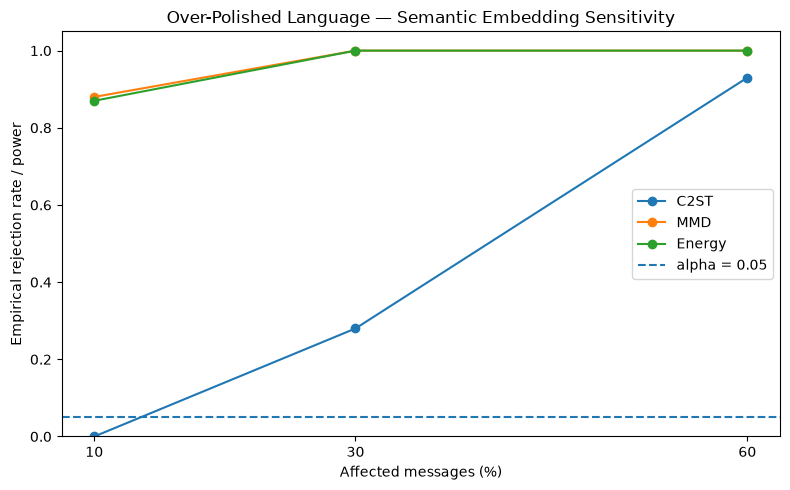

In [52]:
import matplotlib.pyplot as plt


plt.figure(
    figsize=(8, 5)
)


for metric in [
    "C2ST",
    "MMD",
    "Energy"
]:

    subset = (
        over_polished_power_summary[
            over_polished_power_summary[
                "metric"
            ] == metric
        ]
        .sort_values(
            "severity"
        )
    )

    plt.plot(
        subset[
            "severity"
        ] * 100,

        subset[
            "power"
        ],

        marker="o",
        label=metric
    )


plt.axhline(
    ALPHA,
    linestyle="--",
    label="alpha = 0.05"
)

plt.xlabel(
    "Affected messages (%)"
)

plt.ylabel(
    "Empirical rejection rate / power"
)

plt.title(
    "Over-Polished Language — "
    "Semantic Embedding Sensitivity"
)

plt.ylim(
    0,
    1.05
)

plt.xticks(
    [
        10,
        30,
        60
    ]
)

plt.legend()

plt.tight_layout()

plt.show()

In [53]:
from src.metrics import (
    c2st,
    mmd_permutation_test,
    energy_permutation_test
)


In [54]:
# clenas vs independent clean over 300 sms clean embeddings 

NULL_REPS = 200

null_rng = np.random.default_rng(
    BASE_SEED
)

clean_X = (
    over_polished_embeddings[
        "clean"
    ][
        EMBEDDING_FEATURES
    ]
    .to_numpy()
)

null_records = []


for rep in range(
    NULL_REPS
):

    # -----------------------------------------
    # Two independent clean groups
    # -----------------------------------------

    selected = null_rng.choice(
        len(clean_X),
        size=200,
        replace=False
    )

    P = clean_X[
        selected[:100]
    ]

    Q = clean_X[
        selected[100:]
    ]

    seed = (
        BASE_SEED + rep
    )


    # =========================================
    # C2ST
    # =========================================

    result = c2st(
        P,
        Q,
        test_size=0.5,
        seed=seed,
        alpha=ALPHA
    )

    stat, p, reject = (
        extract_metric_result(
            result,
            "C2ST",
            alpha=ALPHA
        )
    )

    null_records.append({
        "repetition":
            rep,

        "metric":
            "C2ST",

        "statistic":
            stat,

        "p_value":
            p,

        "reject":
            reject
    })


    # =========================================
    # MMD
    # =========================================

    result = (
        mmd_permutation_test(
            P,
            Q,
            sigma=(
                OVER_POLISHED_MMD_SIGMA
            ),
            n_permutations=(
                N_PERMUTATIONS
            ),
            seed=seed,
            alpha=ALPHA
        )
    )

    stat, p, reject = (
        extract_metric_result(
            result,
            "MMD",
            alpha=ALPHA
        )
    )

    null_records.append({
        "repetition":
            rep,

        "metric":
            "MMD",

        "statistic":
            stat,

        "p_value":
            p,

        "reject":
            reject
    })


    # =========================================
    # ENERGY
    # =========================================

    result = (
        energy_permutation_test(
            P,
            Q,
            n_permutations=(
                N_PERMUTATIONS
            ),
            seed=seed,
            alpha=ALPHA
        )
    )

    stat, p, reject = (
        extract_metric_result(
            result,
            "Energy",
            alpha=ALPHA
        )
    )

    null_records.append({
        "repetition":
            rep,

        "metric":
            "Energy",

        "statistic":
            stat,

        "p_value":
            p,

        "reject":
            reject
    })


    if (
        (rep + 1) % 20
        == 0
    ):
        print(
            f"Completed "
            f"{rep + 1}/{NULL_REPS} "
            "null repetitions"
        )


over_polished_null_results = (
    pd.DataFrame(
        null_records
    )
)


print(
    "Null results:",
    len(
        over_polished_null_results
    )
)

print(
    "Expected:",
    NULL_REPS * 3
)

Completed 20/200 null repetitions
Completed 40/200 null repetitions
Completed 60/200 null repetitions
Completed 80/200 null repetitions
Completed 100/200 null repetitions
Completed 120/200 null repetitions
Completed 140/200 null repetitions
Completed 160/200 null repetitions
Completed 180/200 null repetitions
Completed 200/200 null repetitions
Null results: 600
Expected: 600


In [57]:
# null summary 
over_polished_null_summary = (
    over_polished_null_results
    .groupby(
        "metric"
    )
    .agg(
        rejections=(
            "reject",
            "sum"
        ),

        type_I_error=(
            "reject",
            "mean"
        ),

        mean_p_value=(
            "p_value",
            "mean"
        )
    )
    .reset_index()
)


display(
    over_polished_null_summary
)

,metric,rejections,type_I_error,mean_p_value
0,C2ST,10,0.050,0.540801
1,Energy,9,0.045,0.524406
2,MMD,10,0.050,0.520347


In [58]:
over_polished_power_summary.to_csv(
    "../results/"
    "over_polished_semantic_power_summary.csv",
    index=False
)

over_polished_null_results.to_csv(
    "../results/"
    "over_polished_semantic_null.csv",
    index=False
)

over_polished_null_summary.to_csv(
    "../results/"
    "over_polished_semantic_null_summary.csv",
    index=False
)

over_polished_affected_summary.to_csv(
    "../results/"
    "over_polished_semantic_affected_summary.csv"
)

print(
    "Over-Polished metric outputs saved."
)

Over-Polished metric outputs saved.


### Over-Polished Language — Paired Sensitivity Results

The clean-vs-clean null experiment confirmed that all three tests were
well calibrated under the individual-message semantic representation.
Empirical Type I error was 0.050 for C2ST, 0.045 for Energy Distance,
and 0.050 for MMD, closely matching the nominal alpha level of 0.05.

Under the injected Over-Polished Language defect, MMD and Energy Distance
showed high sensitivity even at low prevalence. At 10% affected messages,
empirical power was 0.880 for MMD and 0.870 for Energy Distance. Both
metrics reached a power of 1.000 at 30% prevalence and remained saturated
at 60%.

C2ST exhibited substantially lower sensitivity. Its empirical power was
0.000 at 10%, 0.280 at 30%, and 0.930 at 60%. Mean classification
accuracy increased with prevalence, but the linear logistic-regression
classifier required a much larger fraction of polished messages before
reliably separating clean and defective embeddings.

These results are notable because clean and polished message embeddings
remained highly semantically similar, with mean cosine similarity of
approximately 0.97 among affected pairs. Therefore, the polishing
transformation generally preserved semantic content while still inducing
a distributional change that was readily detected by MMD and Energy
Distance.

The combination of near-nominal Type I error and high low-prevalence power
for MMD and Energy suggests that their sensitivity is not caused by
miscalibration. Instead, the result reflects a genuine difference in how
the three tests exploit subtle representation-level changes.

In [59]:
import importlib
import src.io_utils as io_utils

importlib.reload(io_utils)

from src.io_utils import (
    save_embedding_ids
)

In [60]:
clean_message_ids = (
    over_polished_embeddings[
        "clean"
    ]["message_id"]
    .to_numpy()
)


print(
    "Number of clean message IDs:",
    len(clean_message_ids)
)

print(
    "Unique clean message IDs:",
    len(
        np.unique(clean_message_ids)
    )
)

print(
    "First 10 message IDs:"
)

print(
    clean_message_ids[:10]
)

Number of clean message IDs: 300
Unique clean message IDs: 300
First 10 message IDs:
['SMS_0014' 'SMS_0025' 'SMS_0035' 'SMS_0038' 'SMS_0076' 'SMS_0080'
 'SMS_0085' 'SMS_0119' 'SMS_0135' 'SMS_0145']


In [61]:
OVER_POLISHED_CONDITIONS = [
    "clean",
    0.10,
    0.30,
    0.60
]


reference_ids = (
    over_polished_embeddings[
        "clean"
    ]["message_id"]
    .to_numpy()
)


for condition in (
    OVER_POLISHED_CONDITIONS
):

    condition_ids = (
        over_polished_embeddings[
            condition
        ]["message_id"]
        .to_numpy()
    )

    same_order = np.array_equal(
        reference_ids,
        condition_ids
    )

    print(
        f"{condition}: "
        f"same message order = "
        f"{same_order}"
    )

    assert same_order


print(
    "Message ID alignment passed "
    "for all embedding conditions."
)

clean: same message order = True
0.1: same message order = True
0.3: same message order = True
0.6: same message order = True
Message ID alignment passed for all embedding conditions.


In [62]:
OVER_POLISHED_CONDITIONS = [
    "clean",
    0.10,
    0.30,
    0.60
]


reference_ids = (
    over_polished_embeddings[
        "clean"
    ]["message_id"]
    .to_numpy()
)


for condition in (
    OVER_POLISHED_CONDITIONS
):

    condition_ids = (
        over_polished_embeddings[
            condition
        ]["message_id"]
        .to_numpy()
    )

    same_order = np.array_equal(
        reference_ids,
        condition_ids
    )

    print(
        f"{condition}: "
        f"same message order = "
        f"{same_order}"
    )

    assert same_order


print(
    "Message ID alignment passed "
    "for all embedding conditions."
)

clean: same message order = True
0.1: same message order = True
0.3: same message order = True
0.6: same message order = True
Message ID alignment passed for all embedding conditions.


In [63]:
for condition in (
    OVER_POLISHED_CONDITIONS
):

    X = (
        over_polished_embedding_arrays[
            condition
        ]
    )

    ids = (
        over_polished_embeddings[
            condition
        ]["message_id"]
        .to_numpy()
    )

    print(
        f"{condition}: "
        f"embeddings={X.shape}, "
        f"IDs={len(ids)}"
    )

    assert (
        X.shape[0]
        ==
        len(ids)
    )


print(
    "Each embedding row has "
    "exactly one message ID."
)

clean: embeddings=(300, 384), IDs=300
0.1: embeddings=(300, 384), IDs=300
0.3: embeddings=(300, 384), IDs=300
0.6: embeddings=(300, 384), IDs=300
Each embedding row has exactly one message ID.


In [64]:
over_polished_id_df = (
    save_embedding_ids(
        over_polished_embeddings[
            "clean"
        ]["message_id"]
        .to_numpy(),

        "../data/processed/"
        "over_polished_"
        "embedding_message_ids.csv",

        id_column="message_id"
    )
)


print(
    "Saved message-ID mapping:",
    over_polished_id_df.shape
)

display(
    over_polished_id_df.head()
)

Saved message-ID mapping: (300, 1)


,message_id
0,SMS_0014
1,SMS_0025
2,SMS_0035
3,SMS_0038
4,SMS_0076


In [65]:
from pathlib import Path

Path(
    "../data/processed"
).mkdir(
    parents=True,
    exist_ok=True
)


for condition in (
    OVER_POLISHED_CONDITIONS
):

    condition_name = (
        "clean"
        if condition == "clean"
        else f"{int(condition * 100)}pct"
    )

    np.save(
        "../data/processed/"
        f"over_polished_embeddings_"
        f"{condition_name}.npy",

        over_polished_embedding_arrays[
            condition
        ]
    )


print(
    "Over-Polished evaluation "
    "embeddings saved."
)

Over-Polished evaluation embeddings saved.


In [66]:
np.save(
    "../data/processed/"
    "over_polished_reference_embeddings.npy",

    over_polished_reference_embeddings
)

In [67]:
save_embedding_ids(
    over_polished_text_sets[
        "reference"
    ]["message_id"]
    .to_numpy(),

    "../data/processed/"
    "over_polished_"
    "reference_embedding_message_ids.csv",

    id_column="message_id"
)

,message_id
0,SMS_0020
1,SMS_0027
2,SMS_0031
3,SMS_0043
4,SMS_0053
...,...
695,SMS_5501
696,SMS_5525
697,SMS_5527
698,SMS_5533


In [68]:
over_polished_embedding_change_summary.to_csv(
    "../results/"
    "over_polished_"
    "embedding_change_summary.csv",
    index=False
)


print(
    "Embedding-change summary saved."
)

Embedding-change summary saved.


In [71]:
import importlib
import src.io_utils as io_utils

importlib.reload(io_utils)

from src.io_utils import (
    save_affected_ids_by_severity
)


over_polished_affected_ids = {
    severity:
        over_polished_results[
            severity
        ]["audit"][
            "message_id"
        ].to_numpy()

    for severity in [
        0.10,
        0.30,
        0.60
    ]
}


over_polished_affected_df = (
    save_affected_ids_by_severity(
        over_polished_affected_ids,

        "../data/processed/"
        "over_polished_"
        "affected_message_ids.csv",

        id_column="message_id"
    )
)


display(
    over_polished_affected_df
    .groupby("severity")
    .size()
)

severity
0.1     30
0.3     90
0.6    180
dtype: int64